In [1]:
words = open('names.txt', 'r').read().splitlines()

In [2]:
words[:10]

['emma',
 'olivia',
 'ava',
 'isabella',
 'sophia',
 'charlotte',
 'mia',
 'amelia',
 'harper',
 'evelyn']

In [3]:
min(len(word) for word in words)

2

In [4]:
max(len(word) for word in words)

15

In [5]:
b = {}

for w in words:
    chs = ['<S>'] + list(w)+ ['<E>']
    for ch1, ch2 in zip(chs, chs[1:]):
        bigram = (ch1, ch2)
        b[bigram] = b.get(bigram, 0) + 1
    

In [6]:
list(zip(words[0], words[0][1:]))

[('e', 'm'), ('m', 'm'), ('m', 'a')]

In [7]:
b.items()

dict_items([(('<S>', 'e'), 1531), (('e', 'm'), 769), (('m', 'm'), 168), (('m', 'a'), 2590), (('a', '<E>'), 6640), (('<S>', 'o'), 394), (('o', 'l'), 619), (('l', 'i'), 2480), (('i', 'v'), 269), (('v', 'i'), 911), (('i', 'a'), 2445), (('<S>', 'a'), 4410), (('a', 'v'), 834), (('v', 'a'), 642), (('<S>', 'i'), 591), (('i', 's'), 1316), (('s', 'a'), 1201), (('a', 'b'), 541), (('b', 'e'), 655), (('e', 'l'), 3248), (('l', 'l'), 1345), (('l', 'a'), 2623), (('<S>', 's'), 2055), (('s', 'o'), 531), (('o', 'p'), 95), (('p', 'h'), 204), (('h', 'i'), 729), (('<S>', 'c'), 1542), (('c', 'h'), 664), (('h', 'a'), 2244), (('a', 'r'), 3264), (('r', 'l'), 413), (('l', 'o'), 692), (('o', 't'), 118), (('t', 't'), 374), (('t', 'e'), 716), (('e', '<E>'), 3983), (('<S>', 'm'), 2538), (('m', 'i'), 1256), (('a', 'm'), 1634), (('m', 'e'), 818), (('<S>', 'h'), 874), (('r', 'p'), 14), (('p', 'e'), 197), (('e', 'r'), 1958), (('r', '<E>'), 1377), (('e', 'v'), 463), (('v', 'e'), 568), (('l', 'y'), 1588), (('y', 'n'), 18

In [8]:
sorted(b.items(), key = lambda kv: -kv[1])

[(('n', '<E>'), 6763),
 (('a', '<E>'), 6640),
 (('a', 'n'), 5438),
 (('<S>', 'a'), 4410),
 (('e', '<E>'), 3983),
 (('a', 'r'), 3264),
 (('e', 'l'), 3248),
 (('r', 'i'), 3033),
 (('n', 'a'), 2977),
 (('<S>', 'k'), 2963),
 (('l', 'e'), 2921),
 (('e', 'n'), 2675),
 (('l', 'a'), 2623),
 (('m', 'a'), 2590),
 (('<S>', 'm'), 2538),
 (('a', 'l'), 2528),
 (('i', '<E>'), 2489),
 (('l', 'i'), 2480),
 (('i', 'a'), 2445),
 (('<S>', 'j'), 2422),
 (('o', 'n'), 2411),
 (('h', '<E>'), 2409),
 (('r', 'a'), 2356),
 (('a', 'h'), 2332),
 (('h', 'a'), 2244),
 (('y', 'a'), 2143),
 (('i', 'n'), 2126),
 (('<S>', 's'), 2055),
 (('a', 'y'), 2050),
 (('y', '<E>'), 2007),
 (('e', 'r'), 1958),
 (('n', 'n'), 1906),
 (('y', 'n'), 1826),
 (('k', 'a'), 1731),
 (('n', 'i'), 1725),
 (('r', 'e'), 1697),
 (('<S>', 'd'), 1690),
 (('i', 'e'), 1653),
 (('a', 'i'), 1650),
 (('<S>', 'r'), 1639),
 (('a', 'm'), 1634),
 (('l', 'y'), 1588),
 (('<S>', 'l'), 1572),
 (('<S>', 'c'), 1542),
 (('<S>', 'e'), 1531),
 (('j', 'a'), 1473),
 (

In [9]:
import torch

In [11]:
N = torch.zeros((27, 27), dtype=torch.int32)

In [12]:
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}

In [13]:
for w in words:
    chs = ['.'] + list(w)+ ['.']
    for ch1, ch2 in zip(chs, chs[1:]):
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        N[ix1, ix2] += 1

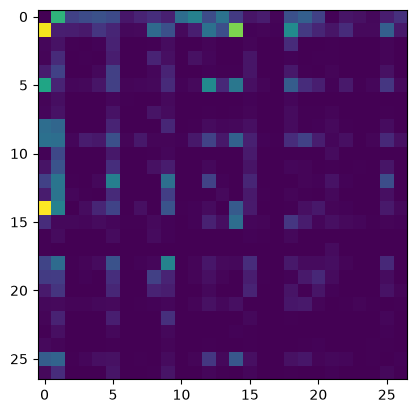

In [14]:
import matplotlib.pyplot as plt
%matplotlib inline
plt.imshow(N)

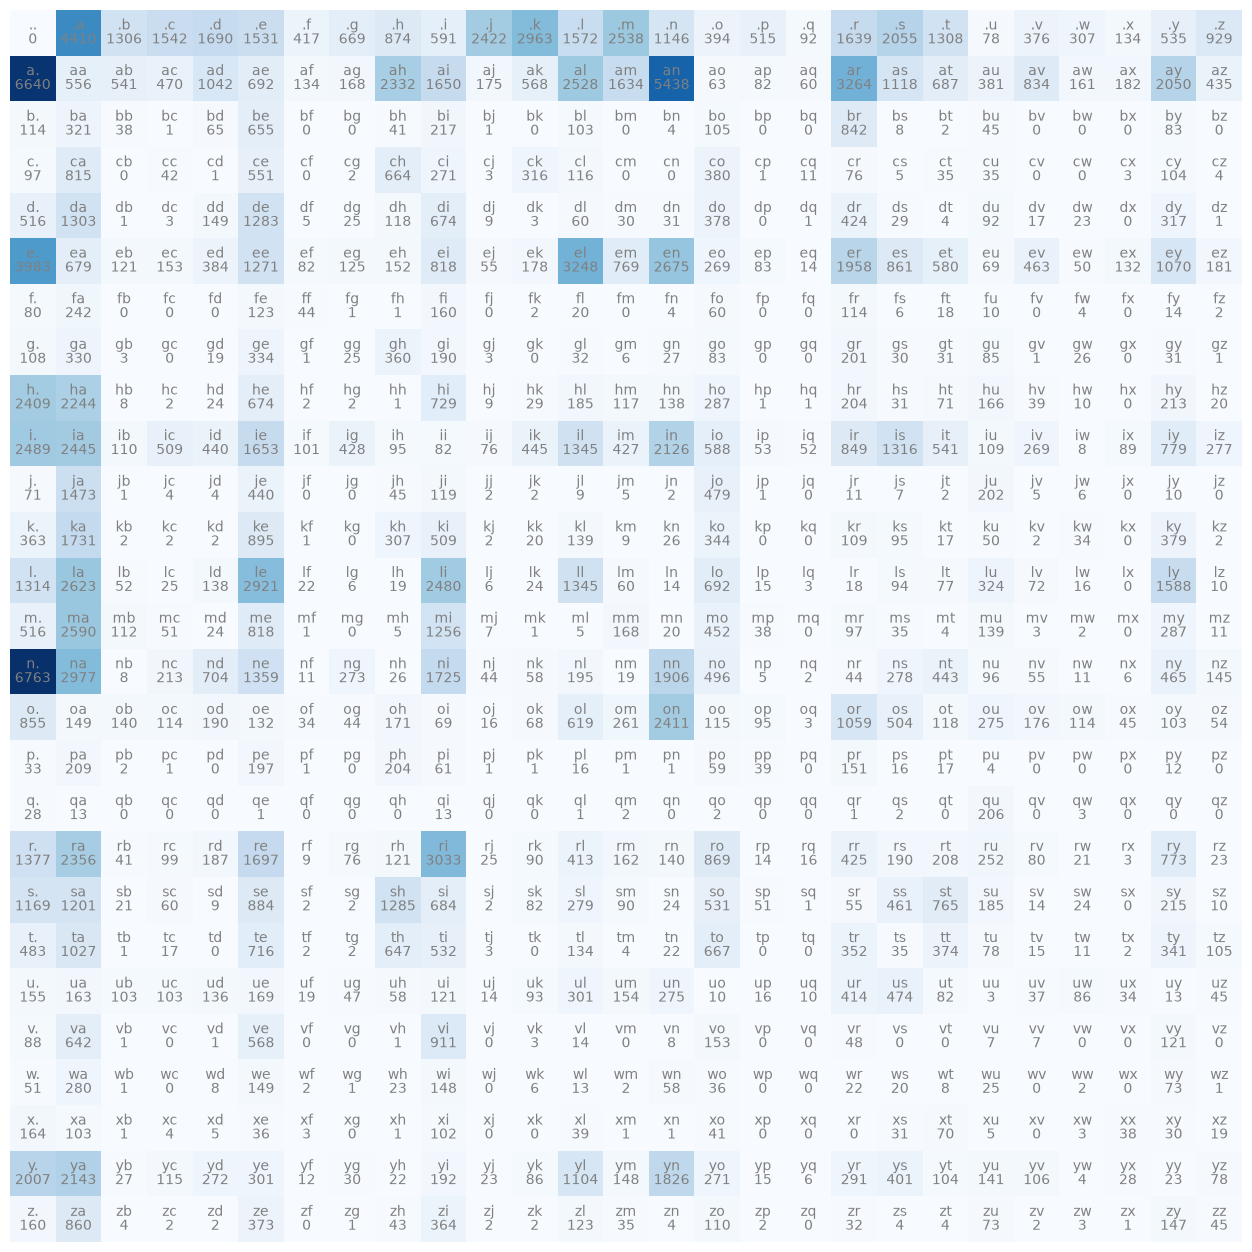

In [15]:
plt.figure(figsize=(16,16))
plt.imshow(N, cmap='Blues')
for i in range(27):
    for j in range(27):
        chstr = itos[i] + itos[j]
        plt.text(j, i, chstr, ha="center", va="bottom", color='gray')
        plt.text(j, i, N[i, j].item(), ha="center", va="top", color='gray')
plt.axis('off');

In [16]:
N[0]

tensor([   0, 4410, 1306, 1542, 1690, 1531,  417,  669,  874,  591, 2422, 2963,
        1572, 2538, 1146,  394,  515,   92, 1639, 2055, 1308,   78,  376,  307,
         134,  535,  929], dtype=torch.int32)

In [17]:
p = N[0].float()
p = p / p.sum()
p

tensor([0.0000, 0.1377, 0.0408, 0.0481, 0.0528, 0.0478, 0.0130, 0.0209, 0.0273,
        0.0184, 0.0756, 0.0925, 0.0491, 0.0792, 0.0358, 0.0123, 0.0161, 0.0029,
        0.0512, 0.0642, 0.0408, 0.0024, 0.0117, 0.0096, 0.0042, 0.0167, 0.0290])

In [18]:
g = torch.Generator().manual_seed(2147483647)
ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
itos[ix]

'c'

In [19]:
g = torch.Generator().manual_seed(2147483647)
p = torch.rand(3, generator=g)
p /= p.sum()
p, p.sum()

(tensor([0.6064, 0.3033, 0.0903]), tensor(1.))

In [20]:
torch.multinomial(p, num_samples=20, replacement=True, generator=g)

tensor([1, 1, 2, 0, 0, 2, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1])

In [46]:
P = N.float()

In [50]:
P.sum(0, keepdim=True)

tensor([[32033., 33885.,  2645.,  3532.,  5496., 20423.,   905.,  1927.,  7616.,
         17701.,  2900.,  5040., 13958.,  6642., 18327.,  7934.,  1026.,   272.,
         12700.,  8106.,  5570.,  3135.,  2573.,   929.,   697.,  9776.,  2398.]])

tensor(32033.)

In [33]:
P.shape

torch.Size([27, 27])

In [56]:
P /= P.sum(0, keepdim=True)

tensor([[0.0000e+00, 1.3015e-01, 4.9376e-01, 4.3658e-01, 3.0750e-01, 7.4965e-02,
         4.6077e-01, 3.4717e-01, 1.1476e-01, 3.3388e-02, 8.3517e-01, 5.8790e-01,
         1.1262e-01, 3.8211e-01, 6.2531e-02, 4.9660e-02, 5.0195e-01, 3.3824e-01,
         1.2906e-01, 2.5352e-01, 2.3483e-01, 2.4880e-02, 1.4613e-01, 3.3046e-01,
         1.9225e-01, 5.4726e-02, 3.8741e-01],
        [2.0729e-01, 1.6408e-02, 2.0454e-01, 1.3307e-01, 1.8959e-01, 3.3883e-02,
         1.4807e-01, 8.7182e-02, 3.0620e-01, 9.3215e-02, 6.0345e-02, 1.1270e-01,
         1.8111e-01, 2.4601e-01, 2.9672e-01, 7.9405e-03, 7.9922e-02, 2.2059e-01,
         2.5701e-01, 1.3792e-01, 1.2334e-01, 1.2153e-01, 3.2414e-01, 1.7330e-01,
         2.6112e-01, 2.0970e-01, 1.8140e-01],
        [3.5588e-03, 9.4732e-03, 1.4367e-02, 2.8313e-04, 1.1827e-02, 3.2072e-02,
         0.0000e+00, 0.0000e+00, 5.3834e-03, 1.2259e-02, 3.4483e-04, 0.0000e+00,
         7.3793e-03, 0.0000e+00, 2.1826e-04, 1.3234e-02, 0.0000e+00, 0.0000e+00,
         6.6299e-

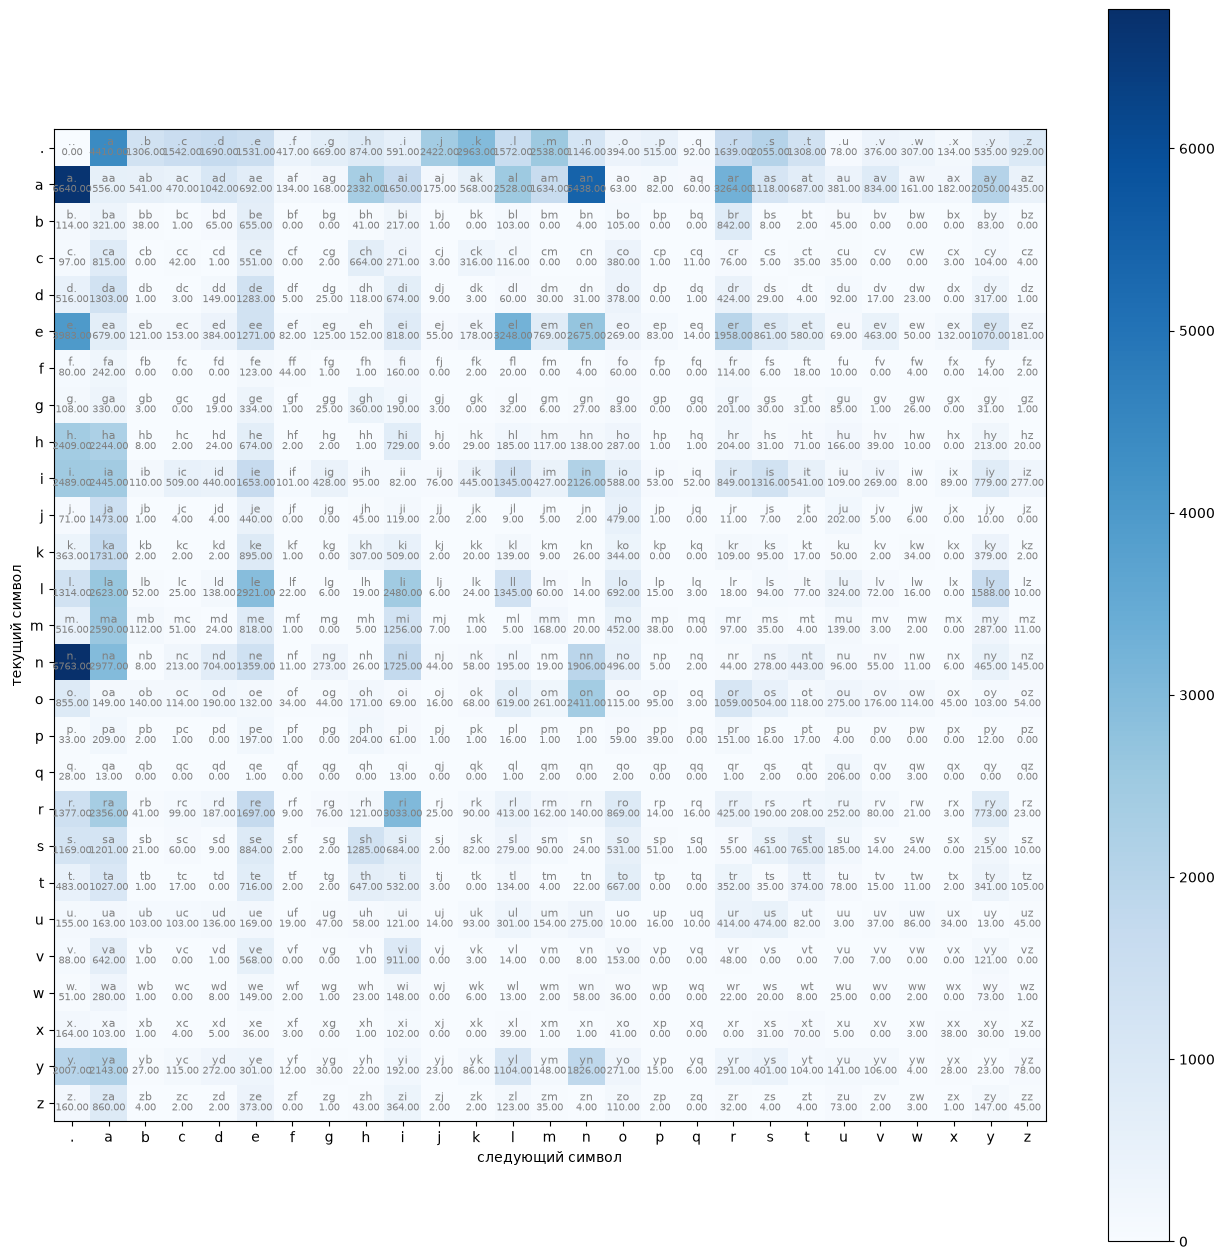

In [47]:

# P — тензор вероятностей [27, 27]
# itos — словарь индекс -> символ, например {0: '.', 1: 'a', ...}
itos = {0: '.', **{i + 1: chr(ord('a') + i) for i in range(26)}}

P_np = P.detach().cpu().numpy()

plt.figure(figsize=(16, 16))
plt.imshow(P_np, cmap='Blues')

for i in range(27):
    for j in range(27):
        plt.text(j, i, itos[i] + itos[j], ha='center', va='bottom', color='gray', fontsize=8)
        plt.text(j, i, f'{P_np[i, j]:.2f}', ha='center', va='top', color='gray', fontsize=7)

plt.xticks(range(27), [itos[i] for i in range(27)])
plt.yticks(range(27), [itos[i] for i in range(27)])
plt.xlabel('следующий символ')
plt.ylabel('текущий символ')
plt.colorbar()
plt.show()

In [35]:
for _ in range(10):
    out = []

    ix = 0
    while True:
        p = N[ix]
        p = p / p.sum()
        ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
        out.append(itos[ix])
        if ix == 0:
            break
    print(''.join(out))
    

l.
mragi.
celadahereneyuerlizeniquiai.
kowasiarey.
min.
t.
zolabesh.
beriamein.
chs.
heicli.
